Single allele groupped structue models.

In [1]:
import numpy as np

import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/single_allele_balanced_data_base_model_viterbi_playground/" #!CHANGE for bwv!

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-DPA1*01:03-DPB1*04:01',
 'HLA-B*07:02',
 'HLA-B*27:05',
 'HLA-A*02:01',
 'HLA-DRB1*04:01',
 'HLA-A*03:01',
 'HLA-DRB1*01:01',
 'HLA-A*01:01']

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [108]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
# ALLELES = sorted([ 'HLA-A*03:01'])

ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])

combination_size = 2
TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
TARGET_LENGTHS= [13, 14, 15, 16, 17, 18]
# TARGET_LENGTHS= [15]
# TARGET_LENGTHS= [8, 9, 10, 11, 12]

In [109]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DPA1*01:03-DPB1*04:01+HLA-DRB1*01:01
Length 9: HLA-DPA1*01:03-DPB1*04:01 - 14 HLA-DRB1*01:01 - 113 
Length 10: HLA-DPA1*01:03-DPB1*04:01 - 68 HLA-DRB1*01:01 - 123 
Length 11: HLA-DPA1*01:03-DPB1*04:01 - 288 HLA-DRB1*01:01 - 175 
Length 12: HLA-DPA1*01:03-DPB1*04:01 - 725 HLA-DRB1*01:01 - 368 
Length 13: HLA-DPA1*01:03-DPB1*04:01 - 1366 HLA-DRB1*01:01 - 826 
Length 14: HLA-DPA1*01:03-DPB1*04:01 - 1802 HLA-DRB1*01:01 - 1184 
Length 15: HLA-DPA1*01:03-DPB1*04:01 - 2260 HLA-DRB1*01:01 - 6886 
Length 16: HLA-DPA1*01:03-DPB1*04:01 - 1580 HLA-DRB1*01:01 - 1413 
Length 17: HLA-DPA1*01:03-DPB1*04:01 - 1160 HLA-DRB1*01:01 - 984 
Length 18: HLA-DPA1*01:03-DPB1*04:01 - 756 HLA-DRB1*01:01 - 708 
Length 19: HLA-DPA1*01:03-DPB1*04:01 - 460 HLA-DRB1*01:01 - 316 
Length 20: HLA-DPA1*01:03-DPB1*04:01 - 299 HLA-DRB1*01:01 - 505 
Length 21: HLA-DPA1*01:03-DPB1*04:01 - 165 HLA-DRB1*01:01 - 177 
Length 22: HLA-DPA1*01:03-DPB1*04:01 - 108 HLA-DRB1*01:01 - 80 
Length 23: HLA-DPA1*01:03-DPB1*04:01 - 74 HLA

In [110]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

In [111]:
import logomaker
peptides = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][13]


In [112]:
selected = [peptide for peptide in peptides if peptide[0] in {'L', 'Y', 'F', 'W'} and peptide[3] not in {'L', 'Y', 'F', 'W'} ]

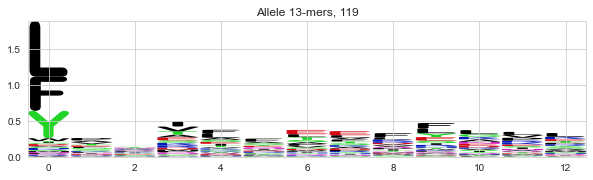

In [9]:
make_logo_for_data(selected, "13-mers")

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [112]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [113]:
count_df_train.index.levels

FrozenList([['HLA-DPA1*01:03-DPB1*04:01', 'HLA-DRB1*01:01'], [0, 1, 2, 3, 4], [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30]])

## 2.3 Weights for data based on counts

In [114]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 20925
Weights for lentgh 13 are {'HLA-DPA1*01:03-DPB1*04:01': 15.318448023426061, 'HLA-DRB1*01:01': 25.332929782082324}
Weights for lentgh 14 are {'HLA-DPA1*01:03-DPB1*04:01': 11.612097669256382, 'HLA-DRB1*01:01': 17.67314189189189}
Weights for lentgh 15 are {'HLA-DPA1*01:03-DPB1*04:01': 9.258849557522124, 'HLA-DRB1*01:01': 3.0387743247168166}
Weights for lentgh 16 are {'HLA-DPA1*01:03-DPB1*04:01': 13.24367088607595, 'HLA-DRB1*01:01': 14.80891719745223}
Weights for lentgh 17 are {'HLA-DPA1*01:03-DPB1*04:01': 18.038793103448278, 'HLA-DRB1*01:01': 21.265243902439025}
Weights for lentgh 18 are {'HLA-DPA1*01:03-DPB1*04:01': 27.678571428571427, 'HLA-DRB1*01:01': 29.555084745762713}
Total data length for split 1 is 20925
Weights for lentgh 13 are {'HLA-DPA1*01:03-DPB1*04:01': 15.318448023426061, 'HLA-DRB1*01:01': 25.332929782082324}
Weights for lentgh 14 are {'HLA-DPA1*01:03-DPB1*04:01': 11.612097669256382, 'HLA-DRB1*01:01': 17.658227848101266}
Weights for le

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [115]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles



## 2.2 Train
### 2.2.1 Define treshold

In [116]:
stop_threshold = 0
cutoff = 0.0005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

132.57416666666668

### 2.2.2 Prepare  initial grouped structure models

In [180]:
# Training params
algorithm = 'viterbi'

params = dict()


params['st'] = 7
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 1
params['transition_pseudocount'] = 0
params['verbose'] = True
params['lr_decay'] = 0
params['edge_inertia'] = 0.25
params['distribution_inertia'] = 0
params['groups'] = 7
params['states_per_group'] = 1
params['use_pseudocount'] = True

assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))



In [181]:
from pomegranate import *
import json
import numpy as np
import pandas as pd
from pomegranate.io import BatchedDataGenerator, SequenceGenerator
from hmm_visualization_methods import convert_graph_to_good_format
import networkx as nx
from tqdm import tqdm
from collections import defaultdict

MINUS_INF_CONSTANT = -20
MINUS_INF_CONSTANT_NORMALIZED = -0.5
def init_grouped_structure_model_joiners_and_cycles_here(
        states_per_group=5, # may be int or list of numbers for each group
        number_of_groups=5,
        amino_acids="ACDEFGHIKLMNPQRSTVWY",
        freeze_distr=False,
        CYCLE_PSEUDOCOUNT=1

):

    INTRAGROUP_WEIGHT = 1
    INTERGROUP_WEIGHT = 1

    START_WEIGHT = 1
    TO_CYCLE_WEIGHT = 3
    IN_CYCLE_WEIGHT = 5
    TO_JOINER_WEIGHT = 5
    END_WEIGHT = 1
    FROM_CYCLE_WEIGHT = 1
    amino_acids_list = list(amino_acids)

    joiner_positions = {0: [0], 1: [1]}
    number_of_joiners = sum(len(positions) for positions in joiner_positions.values())
    number_of_groups = number_of_groups

    if type(states_per_group) == list:
        assert number_of_groups == len(states_per_group), f"Number of groups is expected to be {number_of_groups} but got {len(states_per_group)} in a list of states per group"
    else:
        states_per_group = [states_per_group for i in range(number_of_groups)]
    distributions = list()


    # initialize group states
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for state_num in range(states_in_group):
            d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
            d_sum = sum(d_dict.values())
            d_dict = {key: value/d_sum for key, value in d_dict.items()}
            d = DiscreteDistribution(d_dict)
            distributions.append(d)
    #initialize joiner states (random here)
    joiner_label_to_index_in_model = dict()
    for joiner_name in range(number_of_joiners):
        # d = DiscreteDistribution(
        #     {key: prob for key, prob in zip(amino_acids_list, np.random.uniform(0, 1, size=len(amino_acids_list)))})
        d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
        d_sum = sum(d_dict.values())
        d_dict = {key: value/d_sum for key, value in d_dict.items()}
        d = DiscreteDistribution(d_dict)
        joiner_label_to_index_in_model[joiner_name] = len(distributions)

        distributions.append(d)

    # initialize cycle states
    # start_d = None
    # start_d = DiscreteDistribution(
    #             {key: prob for key, prob in zip(amino_acids_list, np.random.uniform(0, 1, size=len(amino_acids_list)))})
    d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
    d_sum = sum(d_dict.values())
    d_dict = {key: value/d_sum for key, value in d_dict.items()}
    start_d = DiscreteDistribution(d_dict)
    if freeze_distr:
        start_d.freeze()
    # end_d = None
    # end_d = DiscreteDistribution(
    #         {key: prob for key, prob in zip(amino_acids_list, np.random.uniform(0, 1, size=len(amino_acids_list)))})
    d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
    d_sum = sum(d_dict.values())
    d_dict = {key: value/d_sum for key, value in d_dict.items()}
    end_d = DiscreteDistribution(d_dict)
    if freeze_distr:
        end_d.freeze()
    distributions.append(start_d)
    distributions.append(end_d)


    # print("joiners positions", joiner_label_to_index_in_model)

    num_states = sum(states_per_group) + number_of_joiners +  2 # groups, joiners, 2 cycles
    state_names = ["s{:03d}".format(i) for i in range(num_states)]

    transition_matrix = numpy.zeros((num_states, num_states))

    # Transitions inside groups
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for i in range(states_in_group):
            # fill transitions inside each group with INTRAGROUP_WEIGHT
            for j in range(states_in_group):
                state_num_from = sum(states_per_group[:group_number]) + i
                state_num_to =  sum(states_per_group[:group_number]) + j
                if state_num_from != state_num_to:
                    transition_matrix[state_num_from][state_num_to] = INTRAGROUP_WEIGHT

            # transition to next group is 1
            if group_number != number_of_groups - 1:
                for j in range(states_in_group):
                    state_num_from = sum(states_per_group[:group_number]) + i
                    state_num_to = sum(states_per_group[:group_number+1]) + j
                    transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT



    model_name = 'grouped_model'


    first_joiner_idx =  sum(states_per_group)
    first_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[0])
    last_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[max(joiner_positions.keys())])
    last_joiner_idx =  sum(states_per_group) + number_of_joiners - 1
    # connect start cycle to the first joiners
    start_cycle_idx = sum(states_per_group) + number_of_joiners
    end_cycle_idx = start_cycle_idx + 1


    # connect first joiner to first group
    for joiner_index in first_joiners:
        group_number = 0
        state_num_from = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_to = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT
    # connect last group to the last joiner
    for joiner_index in last_joiners:
        group_number = group_number -1
        state_num_to = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = TO_JOINER_WEIGHT

    # connect first cycle to first joiner
    for joiner_idx in first_joiners:
        transition_matrix[start_cycle_idx][joiner_idx] = FROM_CYCLE_WEIGHT
    # connect last joiners to last cycle
    for joiner_idx in last_joiners:
        transition_matrix[joiner_idx][end_cycle_idx] = TO_CYCLE_WEIGHT
    #cycle in start and end cycle states
    transition_matrix[end_cycle_idx][end_cycle_idx] = IN_CYCLE_WEIGHT
    transition_matrix[start_cycle_idx][start_cycle_idx] = IN_CYCLE_WEIGHT



    # start only for first cycle and first joiner
    start_probabilities = [START_WEIGHT
                           if i == start_cycle_idx or i in first_joiners
                           else 0
                           for i in range(num_states)]
    start_probabilities[start_cycle_idx] = TO_CYCLE_WEIGHT
    # do not restrict ending in multiple states, so probs are equal to transitions inside

    end_probabilities = [END_WEIGHT
                         if i == end_cycle_idx or i in last_joiners
                         else 0
                         for i in range(num_states)]

    # assert sum(start_probabilities) == len(joiner_positions[0])* START_WEIGHT + TO_CYCLE_WEIGHT, start_probabilities
    # assert sum(end_probabilities) ==  (len(joiner_positions[max(joiner_positions.keys())]) + 1)  * END_WEIGHT, end_probabilities + list(last_joiners)

    model = HiddenMarkovModel.from_matrix(
        name=model_name,
        transition_probabilities=transition_matrix,
        starts=start_probabilities,
        distributions=distributions,
        ends=end_probabilities,
        state_names=state_names,
        verbose=True)
    model.add_transition(model.states[start_cycle_idx], model.states[start_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
    model.add_transition(model.start, model.states[start_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
    for joiner_idx in first_joiners:
        model.add_transition(model.states[start_cycle_idx], model.states[joiner_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)

    model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
    model.add_transition(model.states[end_cycle_idx],model.end, IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
    for joiner_idx in last_joiners:
        model.add_transition(model.states[joiner_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)


        # model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)

    model.bake(verbose=True)
    return model

In [182]:
cycle_pseudocount = 1
model = init_grouped_structure_model_joiners_and_cycles_here(states_per_group=int(params['states_per_group']), number_of_groups=params['groups'], freeze_distr=True, CYCLE_PSEUDOCOUNT=cycle_pseudocount)


grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s006 summed to 5.0, normalized to 1.0
grouped_model : s008 summed to 6.0, normalized to 1.0
grouped_model : s009 summed to 10.0, normalized to 1.0
grouped_model : s010 summed to 10.0, normalized to 1.0


In [183]:
with open('model.png', 'w+') as f:
    model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [184]:
from hmm_visualization_methods import *
plot_distributions_for_states(model,"test/", horizontal=False)

In [185]:
make_pyviz_graph(model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=13 |E|=16

In [186]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [187]:
ten_mer = allele_peptides[12]
ten_mer, len(ten_mer)

('IHFHAESFLYRNG', 13)

In [188]:
prob, path = model.viterbi(ten_mer)

In [189]:
[item[0] for item in path]

[11, 9, 9, 9, 9, 7, 0, 1, 2, 3, 4, 5, 6, 8, 12]

In [190]:
sixteen_mer = allele_peptides[8900]
sixteen_mer, len(sixteen_mer)

('FKEFVEAIGNTLQTP', 15)

In [191]:
sixteen_mer[3]

'F'

In [192]:
pd.DataFrame(model.forward(sixteen_mer))

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-4.479724,-inf,-5.036289,-inf,-inf,-inf
2,-7.227180,-inf,-inf,-inf,-inf,-inf,-inf,-8.445330,-inf,-9.137201,-inf,-inf,-inf
3,-10.955333,-10.769322,-inf,-inf,-inf,-inf,-inf,-13.976301,-inf,-13.431027,-inf,-inf,-inf
4,-19.090116,-13.541184,-13.208865,-inf,-inf,-inf,-inf,-16.812138,-inf,-18.978142,-inf,-inf,-inf
5,-19.540033,-22.858918,-16.549840,-15.942518,-inf,-inf,-inf,-23.125365,-inf,-22.030859,-inf,-inf,-inf
6,-25.635369,-23.082174,-25.948479,-19.970518,-20.061373,-inf,-inf,-26.869959,-inf,-26.324685,-inf,-inf,-inf
7,-30.169011,-28.118213,-28.951771,-28.525399,-23.361801,-23.038940,-inf,-31.374342,-inf,-31.328450,-inf,-inf,-inf
8,-34.668940,-33.434848,-31.244598,-33.885914,-31.228177,-26.157480,-25.379265,-35.231883,-inf,-35.680198,-inf,-inf,-inf
9,-37.822923,-40.355575,-37.262440,-34.602420,-36.404349,-35.356059,-29.238997,-41.038153,-28.292557,-41.648612,-inf,-inf,-30.084316


In [193]:
pd.DataFrame(model.forward_backward(sixteen_mer)[1])

,0,1,2,3,4,5,6,7,8,9,10
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-0.705945,-inf,-0.680511,-inf
1,-0.705945,-inf,-inf,-inf,-inf,-inf,-inf,-0.710273,-inf,-4.209865,-inf
2,-0.710273,-0.705945,-inf,-inf,-inf,-inf,-inf,-4.755614,-inf,-5.075957,-inf
3,-4.755614,-0.710273,-0.705945,-inf,-inf,-inf,-inf,-5.271081,-inf,-6.806052,-inf
4,-5.271081,-4.755614,-0.710273,-0.705945,-inf,-inf,-inf,-6.869503,-inf,-9.595090,-inf
5,-6.869503,-5.271081,-4.755614,-0.710273,-0.705945,-inf,-inf,-10.968065,-inf,-9.887252,-inf
6,-10.968065,-6.869503,-5.271081,-4.755614,-0.710273,-0.705945,-inf,-9.887252,-inf,-inf,-inf
7,-9.887252,-10.968065,-6.869503,-5.271081,-4.755614,-0.710273,-0.705945,-inf,-inf,-inf,-inf
8,-inf,-9.887252,-10.968065,-6.869503,-5.271081,-4.755614,-0.710273,-inf,-0.705945,-inf,-inf
9,-inf,-inf,-9.887252,-10.968065,-6.869503,-5.271081,-4.755614,-inf,-0.710273,-inf,-0.705945


In [194]:
pd.DataFrame(model.forward_backward(ten_mer)[1])

,0,1,2,3,4,5,6,7,8,9,10
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-1.974877,-inf,-0.149403,-inf
1,-1.974877,-inf,-inf,-inf,-inf,-inf,-inf,-5.433390,-inf,-0.154488,-inf
2,-5.433390,-1.974877,-inf,-inf,-inf,-inf,-inf,-2.447165,-inf,-0.260956,-inf
3,-2.447165,-5.433390,-1.974877,-inf,-inf,-inf,-inf,-3.348219,-inf,-0.307656,-inf
4,-3.348219,-2.447165,-5.433390,-1.974877,-inf,-inf,-inf,-0.307656,-inf,-inf,-inf
5,-0.307656,-3.348219,-2.447165,-5.433390,-1.974877,-inf,-inf,-inf,-inf,-inf,-inf
6,-inf,-0.307656,-3.348219,-2.447165,-5.433390,-1.974877,-inf,-inf,-inf,-inf,-inf
7,-inf,-inf,-0.307656,-3.348219,-2.447165,-5.433390,-1.974877,-inf,-inf,-inf,-inf
8,-inf,-inf,-inf,-0.307656,-3.348219,-2.447165,-5.433390,-inf,-1.974877,-inf,-inf
9,-inf,-inf,-inf,-inf,-0.307656,-3.348219,-2.447165,-inf,-5.433390,-inf,-1.974877


In [195]:
ten_mer

'IHFHAESFLYRNG'

In [196]:
state_sums = [sum(state.distribution.parameters[0].values()) for state in model.states[:-2]]
assert np.isclose(sum(state_sums), len(state_sums))

In [197]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(states_per_group=int(params['states_per_group']), number_of_groups=params['groups'], CYCLE_PSEUDOCOUNT=8000, freeze_distr=True)

            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s006 summed to 5.0, normalized to 1.0
grouped_model : s008 summed to 6.0, normalized to 1.0
grouped_model : s009 summed to 10.0, normalized to 1.0
grouped_model : s010 summed to 10.0, normalized to 1.0
grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s006 summed to 5.0, normalized to 1.0
grouped_model : s008 summed to 6.0, normalized to 1.0
grouped_model : s009 summed to 10.0, normalized to 1.0
grouped_model : s010 summed to 10.0, normalized to 1.0
grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s006 summed to 5.0, normalized to 1.0
grouped_model : s008 summed to 6.0, normalized to 1.0
grouped_model : s009 summed to 10.0, normalized to 1.0
grouped_model : s010 summed to 10.0, normalized to 1.0
grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s006 summed to 5.0, normalized to 1.0
grouped_model : 

In [148]:
# cycle_state = prepared_model.states[27]
# start = prepared_model.states[29]
# prepared_model.graph.edges()[cycle_state, cycle_state]

IndexError: list index out of range

In [198]:
ALLELES

['HLA-DPA1*01:03-DPB1*04:01+HLA-DRB1*01:01']

model

In [199]:
%%time

per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'])
        
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)
        break


run 0
split 0
train size 20925
Shuffling for fairness 
Simple training: Train Length 20925, init_batch_size None
Use pseudocount is True
[1] Improvement: 44184.99026363145	Time (s): 2.451
[2] Improvement: 3480.469110345817	Time (s): 1.911
[3] Improvement: 1407.8451443463564	Time (s): 2.006
[4] Improvement: 883.5492282652995	Time (s): 2.573
[5] Improvement: 484.20948913355824	Time (s): 2.257
[6] Improvement: 341.69364095199853	Time (s): 1.57
[7] Improvement: 301.66351245797705	Time (s): 1.773
[8] Improvement: 290.8315822519362	Time (s): 2.249
[9] Improvement: 350.04069846577477	Time (s): 2.39
[10] Improvement: 320.75673490331974	Time (s): 2.037
[11] Improvement: 306.2854297187878	Time (s): 3.022
[12] Improvement: 316.64485329331364	Time (s): 3.538
[13] Improvement: 334.99873005168047	Time (s): 3.145
[14] Improvement: 490.19163003971335	Time (s): 1.875
[15] Improvement: 513.4147453124169	Time (s): 1.852
[16] Improvement: 453.4430233478779	Time (s): 1.912
[17] Improvement: 357.50978974287

In [200]:
from hmm_visualization_methods import *

In [201]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
Wall time: 188 ms


In [202]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False)
    print(i)

0
Wall time: 4.35 s


In [203]:
from hmm_visualization_methods import *
per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0) (Delete zero edges)


In [ ]:
TARGET_PATH_TO_RESULTS

In [43]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])

In [159]:
ALLELES

['HLA-DPA1*01:03-DPB1*04:01', 'HLA-DRB1*01:01']

In [189]:
peptide = allele_peptides[5]
peptide

'SEAYLVGLFEDTN'

In [190]:
print([item[1].name for item in model.viterbi(peptide)[1]])

['grouped_model-start', 's027', 's027', 's025', 's004', 's005', 's008', 's012', 's016', 's017', 's021', 's022', 's026', 's028', 'grouped_model-end']


In [ ]:
NGFKTQHFV

In [50]:
model.graph.edges()[cycle_state, cycle_state]

{'probability': -1.2327600919633284, 'pseudocount': 8000, 'group': None}